# 09 — Optimization & Trade-off Analysis

**Member 4 — Erlan | NYC Yellow Taxi 2026**

This notebook is aligned with the feature dataset created in `script/05_features.ipynb`.

## Dataset & modeling schema
- Dataset: `datasets/interim/2026/features_dataset.parquet`
- Target: `demand_level` (`Rendah`, `Sedang`, `Tinggi`)
- Features: the same 14 features used in `07_svm_classification.ipynb`
- Train: January–April
- Validation: May
- Test: June (reserved; do not use for tuning/model selection)

## Optimization rules
- Hyperparameter tuning is restricted to Train.
- Use chronological `TimeSeriesSplit`, not shuffled/random K-fold.
- Validation is used for model selection after tuning.
- Test is evaluated only once after the final model is selected.
- Track macro-F1, class metrics, training time, prediction time, and complexity.


In [2]:
# Cek variabel yang tersedia di kernel
print([name for name in globals() if name.endswith("_df")])

[]


In [ ]:
# 1. Imports & configuration
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
TARGET = "demand_level"
LABELS = ["Rendah", "Sedang", "Tinggi"]

FEATURES = [
    "hour_of_day", "day_of_week", "month", "is_weekend", "is_holiday",
    "PU_longitude", "PU_latitude", "is_airport", "is_cbd",
    "lag_1", "lag_24", "lag_168", "roll_24", "roll_168"
]

OUT_CANDIDATES = [Path("out"), Path("../out"), Path("../../out")]
OUT_DIR = next((p for p in OUT_CANDIDATES if p.exists()), OUT_CANDIDATES[0])
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Optimization setup ready.")


## 2. Load dataset and isolate Train

Use the split column generated by feature engineering. No Validation/Test rows are passed to GridSearchCV.

In [ ]:
DATA_CANDIDATES = [
    Path("datasets/interim/2026/features_dataset.parquet"),
    Path("../datasets/interim/2026/features_dataset.parquet"),
    Path("../../datasets/interim/2026/features_dataset.parquet"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), DATA_CANDIDATES[0])
print("Data path:", DATA_PATH.resolve())

if DATA_PATH.exists():
    data = pd.read_parquet(DATA_PATH)
    required = FEATURES + [TARGET, "split", "hour", "zone_id", "target_pickup_count"]
    missing = [c for c in required if c not in data.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    print("Dataset shape:", data.shape)
    display(data.head())
else:
    print("Feature dataset not found. Run script/05_features.ipynb first.")


In [ ]:
if "data" in globals():
    train_df = data.loc[data["split"] == "train"].copy()
    val_df = data.loc[data["split"] == "validation"].copy()
    test_df = data.loc[data["split"] == "test"].copy()

    # Preserve chronological order for time-series CV.
    train_df["hour"] = pd.to_datetime(train_df["hour"])
    train_df = train_df.sort_values(["hour", "zone_id"]).reset_index(drop=True)

    X_train_full = train_df[FEATURES]
    y_train_full = train_df[TARGET].astype(str)
    X_val = val_df[FEATURES]
    y_val = val_df[TARGET].astype(str)

    print("Train:", train_df.shape, "| Validation:", val_df.shape, "| Test reserved:", test_df.shape)
    display(y_train_full.value_counts())


## 3. Training sample for hyperparameter tuning

SVM tuning can be expensive. Use a reproducible capped sample from Train only, then sort sampled rows chronologically before TimeSeriesSplit. Validation and Test remain untouched.

> If the capped sample is too small or classes are rare, adjust `MAX_TUNE_ROWS` after checking class counts.

In [ ]:
MAX_TUNE_ROWS = 40_000

def chronological_train_sample(frame, max_rows, seed=RANDOM_STATE):
    if max_rows is None or len(frame) <= max_rows:
        sampled = frame.copy()
    else:
        sampled = frame.sample(n=max_rows, random_state=seed, stratify=frame[TARGET])
    sampled = sampled.sort_values(["hour", "zone_id"]).reset_index(drop=True)
    return sampled

if "train_df" in globals():
    tune_df = chronological_train_sample(train_df, MAX_TUNE_ROWS)
    X_tune = tune_df[FEATURES]
    y_tune = tune_df[TARGET].astype(str)
    print("Train full:", len(train_df), "Tuning sample:", len(tune_df))
    display(y_tune.value_counts())


## 4. Chronological cross-validation

`TimeSeriesSplit` is applied to the chronologically ordered tuning sample. Each validation fold occurs after its corresponding training fold. All scaling is performed inside the pipeline, so scaler parameters are learned separately within each CV training fold.

In [ ]:
N_SPLITS = 4
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

if "X_tune" in globals():
    fig, ax = plt.subplots(figsize=(10, 3))
    for fold, (tr_idx, va_idx) in enumerate(tscv.split(X_tune)):
        ax.scatter(tr_idx, np.full(len(tr_idx), fold), s=1, label="Train" if fold == 0 else None)
        ax.scatter(va_idx, np.full(len(va_idx), fold), s=1, label="CV validation" if fold == 0 else None)
    ax.set_title("TimeSeriesSplit on Train-only chronological sample")
    ax.set_xlabel("Chronological sampled row index")
    ax.set_ylabel("Fold")
    ax.legend()
    plt.tight_layout()
    plt.show()


## 5. Hyperparameter search

Tune macro-F1 to avoid letting the majority class dominate. Start with a small grid. RBF search is computationally heavier; if runtime is high, reduce the tuning sample or grid.

In [ ]:
linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))
])
linear_params = {"classifier__C": [0.01, 0.1, 1.0, 10.0]}

rbf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf", class_weight="balanced"))
])
rbf_params = {
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__gamma": ["scale", 0.01, 0.1]
}

SCORING = "f1_macro"


In [ ]:
# Tune Linear SVM (Train-only)
if "X_tune" in globals():
    linear_search = GridSearchCV(
        estimator=linear_pipeline,
        param_grid=linear_params,
        scoring=SCORING,
        cv=tscv,
        n_jobs=-1,
        verbose=1
    )
    t0 = time.perf_counter()
    linear_search.fit(X_tune, y_tune)
    linear_search_seconds = time.perf_counter() - t0

    print("Best Linear params:", linear_search.best_params_)
    print("Best Train CV macro-F1:", linear_search.best_score_)
    print("Search seconds:", round(linear_search_seconds, 2))


In [ ]:
# Tune RBF SVM (Train-only)
# If runtime is too long, reduce MAX_TUNE_ROWS or narrow rbf_params.
if "X_tune" in globals():
    rbf_search = GridSearchCV(
        estimator=rbf_pipeline,
        param_grid=rbf_params,
        scoring=SCORING,
        cv=tscv,
        n_jobs=-1,
        verbose=1
    )
    t0 = time.perf_counter()
    rbf_search.fit(X_tune, y_tune)
    rbf_search_seconds = time.perf_counter() - t0

    print("Best RBF params:", rbf_search.best_params_)
    print("Best Train CV macro-F1:", rbf_search.best_score_)
    print("Search seconds:", round(rbf_search_seconds, 2))


## 6. Validation comparison

Evaluate the best candidate from each search on the complete Validation partition (May). This step is model selection; do not use Test (June) here.

In [ ]:
def evaluate_on_validation(name, model, Xv, yv, search_score, search_seconds):
    start = time.perf_counter()
    pred = model.predict(Xv)
    pred_seconds = time.perf_counter() - start
    row = {
        "model": name,
        "accuracy": accuracy_score(yv, pred),
        "precision_macro": precision_score(yv, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(yv, pred, average="macro", zero_division=0),
        "macro_f1_validation": f1_score(yv, pred, average="macro", zero_division=0),
        "macro_f1_train_cv": search_score,
        "search_seconds": search_seconds,
        "validation_prediction_seconds": pred_seconds
    }
    return row, pred

validation_rows, validation_predictions = [], {}

if "linear_search" in globals():
    row, pred = evaluate_on_validation(
        "Linear SVM", linear_search.best_estimator_, X_val, y_val,
        linear_search.best_score_, linear_search_seconds
    )
    validation_rows.append(row)
    validation_predictions["Linear SVM"] = pred

if "rbf_search" in globals():
    row, pred = evaluate_on_validation(
        "RBF SVM", rbf_search.best_estimator_, X_val, y_val,
        rbf_search.best_score_, rbf_search_seconds
    )
    validation_rows.append(row)
    validation_predictions["RBF SVM"] = pred

if validation_rows:
    validation_results = pd.DataFrame(validation_rows).sort_values("macro_f1_validation", ascending=False)
    display(validation_results)
    validation_results.to_csv(OUT_DIR / "svm_optimization_validation.csv", index=False)


In [ ]:
# Confusion matrices for optimized SVM candidates on Validation
for model_name, pred in validation_predictions.items():
    cm = confusion_matrix(y_val, pred, labels=LABELS)
    disp = ConfusionMatrixDisplay(cm, display_labels=LABELS)
    disp.plot(values_format="d")
    plt.title(f"{model_name} — Validation Confusion Matrix")
    plt.tight_layout()
    safe_name = model_name.lower().replace(" ", "_")
    plt.savefig(FIG_DIR / f"optimized_{safe_name}_confusion_matrix.png", dpi=150)
    plt.show()


## 7. Cross-model trade-off table

Merge validation results from other team members **only when their results are available**. Models may predict different targets (regression vs classification), so their metrics are not always directly comparable. Compare model performance within the same task/target, and compare complexity, interpretability, and runtime qualitatively across tasks.

In [ ]:
# Fill with actual results; no fabricated metrics.
tradeoff_template = pd.DataFrame(columns=[
    "model", "task", "validation_metric", "validation_score",
    "train_seconds", "predict_seconds", "complexity",
    "interpretability", "tradeoff_notes"
])
display(tradeoff_template)

# Example qualitative notes (edit after results):
# - Linear SVM: relatively simpler, usually faster than kernel SVM, linear boundary.
# - RBF SVM: flexible non-linear boundary, potentially slower and less interpretable.
# - Ridge/Lasso regression: regression target; metrics differ from classification metrics.
# - SARIMA/Holt-Winters: time-series methods; complexity and runtime depend on configuration.


## 8. Coverage@K — evaluation for pickup-count predictions

Coverage@K is defined as the fraction of actual pickups captured by prioritizing K zones per hour. **This metric requires numeric predicted pickup counts**, not merely SVM class labels.

Use predictions from a regression model (e.g., Ridge/Lasso or time-series model) in a validation table with one row per zone-hour and columns:
- `hour`
- `zone_id`
- `predicted_pickup_count`
- `actual_pickup_count`

For each hour, rank zones by predicted count, select top K, sum actual pickups among selected zones, then divide by total actual pickups that hour. Report both macro-average hourly coverage and pickup-weighted coverage.

If only SVM class predictions are available, you may rank `Tinggi > Sedang > Rendah` as a **separate proxy analysis**, but it is not equivalent to numeric pickup-count ranking and should be labeled accordingly.

In [ ]:
# Coverage@K function for regression predictions
TIME_COL = "hour"
ZONE_COL = "zone_id"
PRED_COUNT_COL = "predicted_pickup_count"
ACTUAL_COUNT_COL = "actual_pickup_count"

def coverage_at_k(prediction_table, k,
                 time_col=TIME_COL, pred_col=PRED_COUNT_COL,
                 actual_col=ACTUAL_COUNT_COL):
    ranked = prediction_table.sort_values(
        [time_col, pred_col], ascending=[True, False]
    )
    top_k = ranked.groupby(time_col, sort=False).head(k)
    actual_total = prediction_table.groupby(time_col)[actual_col].sum()
    captured = top_k.groupby(time_col)[actual_col].sum()
    per_hour = (captured / actual_total.replace(0)).dropna()
    return {
        "K": k,
        "coverage_macro": per_hour.mean(),
        "coverage_weighted": captured.sum() / actual_total.sum(),
        "hours_evaluated": len(per_hour)
    }

# TODO: load regression validation predictions from the relevant teammate's output.
# Example expected file: datasets/interim/2026/validation_zone_predictions.parquet
# prediction_table = pd.read_parquet(...)
# coverage_table = pd.DataFrame([coverage_at_k(prediction_table, k) for k in [1, 3, 5, 10, 20]])
# display(coverage_table)
# coverage_table.to_csv(OUT_DIR / "coverage_at_k_validation.csv", index=False)


In [ ]:
# Plot Coverage@K after coverage_table has been created
if "coverage_table" in globals() and not coverage_table.empty:
    plt.figure(figsize=(8, 5))
    plt.plot(coverage_table["K"], coverage_table["coverage_weighted"], marker="o", label="Pickup-weighted")
    plt.plot(coverage_table["K"], coverage_table["coverage_macro"], marker="o", label="Macro-average hourly")
    plt.xlabel("Number of prioritized zones (K)")
    plt.ylabel("Coverage of actual pickups")
    plt.title("Validation Coverage@K")
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / "coverage_at_k_validation.png", dpi=150)
    plt.show()


## 9. Final model decision

Fill after optimization and validation:

- Selected SVM: 
- Hyperparameters:
- Train CV macro-F1:
- Validation macro-F1:
- Validation accuracy:
- Precision/recall for each demand class:
- Training/search time:
- Prediction time:
- Sampling limitation:
- Comparison with other models (same task/target only):
- Coverage@K result vs baseline (regression prediction required):
- Reason for selection:

**Test data (June) is reserved. Run test evaluation only once after the final model is chosen. Do not invent or report results before running the notebook.**

In [3]:
# Cek variabel yang tersedia di kernel
for name in [
    "df", "val_df", "validation_df", "X_val",
    "y_val", "y_pred", "y_pred_rbf",
    "best_rbf", "optimized_rbf", "rbf_model"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}", 
              getattr(obj, "shape", ""))

In [4]:
import pandas as pd

DATA_PATH = "../datasets/interim/2026/features_dataset.parquet"

df = pd.read_parquet(DATA_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Dataset shape: (1053841, 22)
Columns: ['hour', 'zone_id', 'PU_longitude', 'PU_latitude', 'PU_zone_name', 'PU_borough', 'is_airport', 'is_cbd', 'hour_of_day', 'day_of_week', 'month', 'is_weekend', 'is_holiday', 'is_major_nyc_event', 'lag_1', 'lag_24', 'lag_168', 'roll_24', 'roll_168', 'target_pickup_count', 'demand_level', 'split']


,hour,zone_id,PU_longitude,PU_latitude,PU_zone_name,PU_borough,is_airport,is_cbd,hour_of_day,day_of_week,...,is_holiday,is_major_nyc_event,lag_1,lag_24,lag_168,roll_24,roll_168,target_pickup_count,demand_level,split
0,2026-01-08 00:00:00,1,-74.174,40.691831,Newark Airport,EWR,1,0,0,3,...,0,0,0.0,0.0,0.0,0.25,1.083333,0.0,Rendah,train
1,2026-01-08 01:00:00,1,-74.174,40.691831,Newark Airport,EWR,1,0,1,3,...,0,0,0.0,0.0,0.0,0.25,1.083333,0.0,Rendah,train
2,2026-01-08 02:00:00,1,-74.174,40.691831,Newark Airport,EWR,1,0,2,3,...,0,0,0.0,0.0,1.0,0.25,1.083333,0.0,Rendah,train
3,2026-01-08 03:00:00,1,-74.174,40.691831,Newark Airport,EWR,1,0,3,3,...,0,0,0.0,0.0,0.0,0.25,1.077381,0.0,Rendah,train
4,2026-01-08 04:00:00,1,-74.174,40.691831,Newark Airport,EWR,1,0,4,3,...,0,0,0.0,0.0,3.0,0.25,1.077381,0.0,Rendah,train


In [5]:
# Tampilkan semua kolom secara lengkap
for i, col in enumerate(df.columns):
    print(i, col)

0 hour
1 zone_id
2 PU_longitude
3 PU_latitude
4 PU_zone_name
5 PU_borough
6 is_airport
7 is_cbd
8 hour_of_day
9 day_of_week
10 month
11 is_weekend
12 is_holiday
13 is_major_nyc_event
14 lag_1
15 lag_24
16 lag_168
17 roll_24
18 roll_168
19 target_pickup_count
20 demand_level
21 split


In [6]:
# Cek kolom yang berpotensi menyimpan split data dan pickup aktual
for col in df.columns:
    if any(keyword in col.lower() for keyword in 
            ["split", "pickup", "demand", "count", "target"]):
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False).head(10))


--- target_pickup_count ---
target_pickup_count
0.0    423397
1.0    142164
2.0     79794
3.0     51499
4.0     35587
5.0     26473
6.0     20681
7.0     16522
8.0     13483
9.0     11506
Name: count, dtype: int64

--- demand_level ---
demand_level
Rendah    423397
Tinggi    321400
Sedang    309044
Name: count, dtype: int64

--- split ---
split
train         668809
validation    195672
test          189360
Name: count, dtype: int64


In [7]:
import numpy as np
import pandas as pd
import time

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import f1_score

FEATURES = [
    "hour_of_day", "day_of_week", "month", "is_weekend",
    "is_holiday", "is_major_nyc_event",
    "PU_longitude", "PU_latitude", "is_airport", "is_cbd",
    "lag_1", "lag_24", "lag_168", "roll_24", "roll_168"
]

TARGET = "demand_level"

# Pisahkan train dan validation saja
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()

# Sampling train seimbang, 5.000 per kelas
sample_parts = []

for label in train_df[TARGET].unique():
    group = train_df[train_df[TARGET] == label]
    sample_parts.append(
        group.sample(n=min(5000, len(group)), random_state=42)
    )

rbf_train = pd.concat(sample_parts, ignore_index=True)

# Scaling, fit hanya dari train
scaler = StandardScaler()

X_train = scaler.fit_transform(rbf_train[FEATURES])
X_val = scaler.transform(val_df[FEATURES])

y_train = rbf_train[TARGET]
y_val = val_df[TARGET]

# Optimized RBF SVM
model = SVC(
    kernel="rbf",
    C=10,
    gamma=0.01,
    class_weight="balanced",
    random_state=42
)

start = time.time()
model.fit(X_train, y_train)
training_time = time.time() - start

start = time.time()
y_pred = model.predict(X_val)
prediction_time = time.time() - start

print("Training time:", round(training_time, 2), "seconds")
print("Prediction time:", round(prediction_time, 2), "seconds")
print("Validation Macro F1:", round(f1_score(y_val, y_pred, average="macro"), 4))
print("Validation predictions:", len(y_pred))

Training time: 6.56 seconds
Prediction time: 198.81 seconds
Validation Macro F1: 0.764
Validation predictions: 195672


In [8]:
# Gabungkan hasil prediksi ke validation dataframe
coverage_df = val_df.copy()
coverage_df["predicted_demand"] = y_pred

# Ranking kategori prediksi
demand_rank = {
    "Rendah": 1,
    "Sedang": 2,
    "Tinggi": 3
}

coverage_df["predicted_rank"] = coverage_df["predicted_demand"].map(demand_rank)

# Fungsi Coverage@K per jam
def calculate_hourly_coverage(data, ranking_columns, k_values=(10, 20, 50)):
    results = []

    for hour, group in data.groupby("hour"):
        group = group.copy()

        total_pickups = group["target_pickup_count"].sum()

        if total_pickups == 0:
            continue

        for k in k_values:
            selected = group.sort_values(
                ranking_columns,
                ascending=False
            ).head(k)

            coverage = (
                selected["target_pickup_count"].sum()
                / total_pickups
            )

            results.append({
                "hour": hour,
                "K": k,
                "covered_pickups": selected["target_pickup_count"].sum(),
                "total_pickups": total_pickups,
                "coverage": coverage
            })

    return pd.DataFrame(results)


# Coverage berdasarkan SVM
svm_coverage = calculate_hourly_coverage(
    coverage_df,
    ["predicted_rank", "lag_1"]
)

# Coverage baseline: lag_1
baseline_coverage = calculate_hourly_coverage(
    coverage_df,
    ["lag_1"]
)

# Agregasi coverage seluruh jam (weighted by actual pickups)
def aggregate_coverage(hourly_result, method_name):
    summary = (
        hourly_result.groupby("K")
        .agg(
            covered_pickups=("covered_pickups", "sum"),
            total_pickups=("total_pickups", "sum")
        )
        .reset_index()
    )

    summary["Coverage"] = (
        summary["covered_pickups"] / summary["total_pickups"]
    )

    summary["Method"] = method_name

    return summary


svm_summary = aggregate_coverage(svm_coverage, "SVM")
baseline_summary = aggregate_coverage(baseline_coverage, "Baseline (lag_1)")

coverage_comparison = pd.concat(
    [svm_summary, baseline_summary],
    ignore_index=True
)

display(
    coverage_comparison[
        ["Method", "K", "covered_pickups", "total_pickups", "Coverage"]
    ]
)

,Method,K,covered_pickups,total_pickups,Coverage
0,SVM,10,1496167.0,3999128.0,0.374123
1,SVM,20,2390194.0,3999128.0,0.597679
2,SVM,50,3591125.0,3999128.0,0.897977
3,Baseline (lag_1),10,1506381.0,3999128.0,0.376677
4,Baseline (lag_1),20,2402443.0,3999128.0,0.600742
5,Baseline (lag_1),50,3604131.0,3999128.0,0.901229


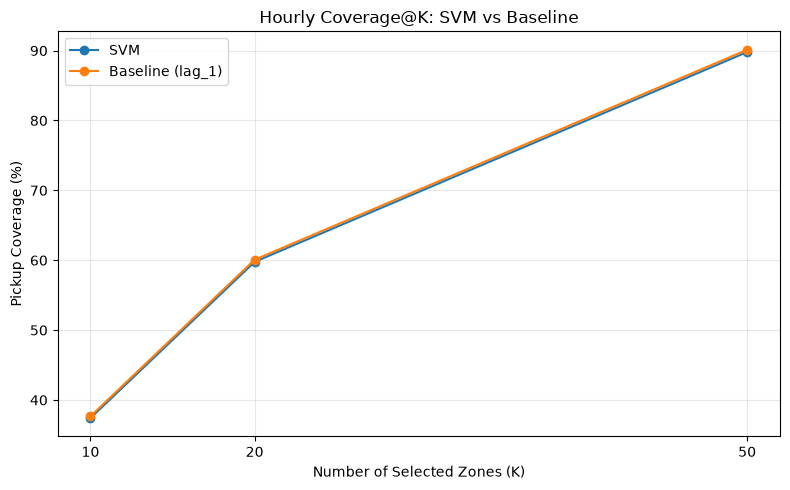

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for method in coverage_comparison["Method"].unique():
    subset = coverage_comparison[
        coverage_comparison["Method"] == method
    ]

    plt.plot(
        subset["K"],
        subset["Coverage"] * 100,
        marker="o",
        label=method
    )

plt.xlabel("Number of Selected Zones (K)")
plt.ylabel("Pickup Coverage (%)")
plt.title("Hourly Coverage@K: SVM vs Baseline")
plt.xticks([10, 20, 50])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()